In [12]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import math

img = cv.imread("capt_baby_inter_1.png")
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

In [13]:
kernel_moyen = cv.getStructuringElement(cv.MORPH_ELLIPSE, (11, 11))
kernel_gros = cv.getStructuringElement(cv.MORPH_ELLIPSE, (21, 21))
#kernel_close = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))
kernel_petit = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
#proportion du kernbel possiblement a changer en fonction des résultats

#NOTE POUR LES MODIFS FUTURES: la taille d'un kernel MORPH_ELLIPSE doit être impaire


In [14]:
mask_green = cv.inRange(hsv, (40, 60, 50), (85, 170, 255))
mask_blue  = cv.inRange(hsv, (100, 150, 50), (130, 255, 255))
#les masques originaux pour les couleurs bleus et vertes

#Valeur pipette du terrain:
# claire (78.0, 96.9, 109.65) convertit
# sombre (72.5, 119.85, 43.35)

print(6 / 2)
print(41 * 255 / 100)
print(38 * 255 / 100)



3.0
104.55
96.9


opened = cv.morphologyEx(border, cv.MORPH_CLOSE, kernel_moyen, iterations=2)
opened = cv.morphologyEx(opened, cv.MORPH_OPEN, kernel_petit, iterations=13)
opened = cv.morphologyEx(opened, cv.MORPH_OPEN, kernel_gros, iterations=2)
#opened = cv.morphologyEx(opened, cv.MORPH_OPEN, kernel_petit, iterations=8) L'originale, ca marchait bien
opened = cv.morphologyEx(opened, cv.MORPH_CLOSE, kernel_gros, iterations=8)

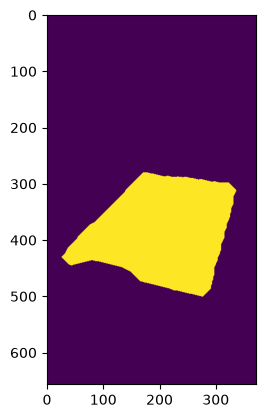

In [15]:
def masked_g_b(param_img):
    hsv = cv.cvtColor(param_img, cv.COLOR_BGR2HSV)
    mask_green_1 = cv.inRange(hsv, (41, 52, 43), (90, 140, 220))

    mask_green_2 = cv.inRange(hsv, (40, 65, 50), (85, 170, 255))
    #mask_blue  = cv.inRange(hsv, (100, 150, 50), (130, 255, 255))


    #masque a revoir, surtout pour le vert

    lower = np.array((41, 52, 43))
    upper = np.array((90, 140, 220))

    mask = cv.inRange(hsv, lower, upper)

    #ajout de la bordure temporaire pour éviter l'effet ventouse du bord sur la fermeture
    largeur_bordure = 60
    border = cv.copyMakeBorder(mask_green_1, largeur_bordure, largeur_bordure, largeur_bordure, largeur_bordure, borderType=cv.BORDER_REPLICATE)    

    opened = cv.morphologyEx(border, cv.MORPH_OPEN, kernel_petit, iterations=3)
    opened = cv.morphologyEx(opened, cv.MORPH_CLOSE, kernel_moyen, iterations=3)
    opened = cv.morphologyEx(opened, cv.MORPH_OPEN, kernel_petit, iterations=13)
    #opened = cv.morphologyEx(opened, cv.MORPH_OPEN, kernel_gros, iterations=2)
    #opened = cv.morphologyEx(opened, cv.MORPH_OPEN, kernel_petit, iterations=8) L'originale, ca marchait bien
    opened = cv.morphologyEx(opened, cv.MORPH_CLOSE, kernel_gros, iterations=8)

    #suppression de la bordure temporaire
    opened = opened[largeur_bordure:opened.shape[0] - largeur_bordure,
                    largeur_bordure:opened.shape[1] - largeur_bordure]
    
    # le paramètre border_type permet de ne pas avoir l'effet vantouse du masque vers le bord quand celui ci s'en approche
    return opened

img_new = cv.imread("image_debugg/_autre_test.png")
plt.imshow(masked_g_b(img_new))
#plt.imshow(masked_g_b(img_new))

Recherche des contours par rapport au masque réalisé précédement

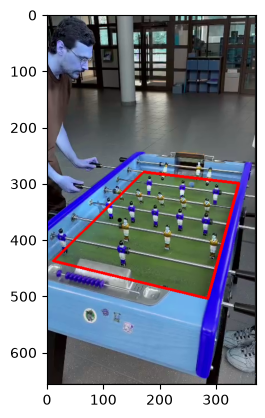

In [16]:
def apply_rectangular_contour(img):
    test_forme = masked_g_b(img)

    contours, _ = cv.findContours(test_forme, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    #cnt = contours[0]
    cnt = max(contours, key=cv.contourArea)
    pre_hull = cv.convexHull(cnt)
    if len(pre_hull) != 0:
        approx = cv.approxPolyN(pre_hull, 4,True)
        cv.drawContours(img, approx, -1, (255,0,0), 3)

    return img

img_conto = cv.imread("image_debugg/_autre_test.png")
plt.imshow(apply_rectangular_contour(img_conto))


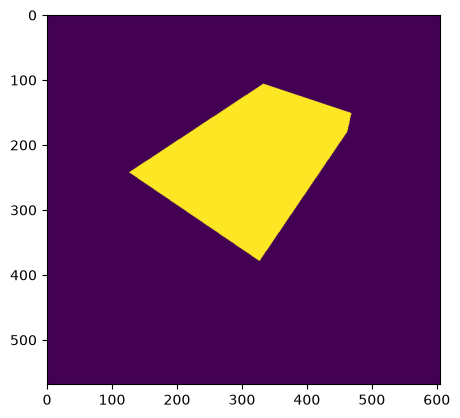

In [17]:
def apply_rectangular_contour_masque(img):
    test_forme = masked_g_b(img)

    contours, _ = cv.findContours(test_forme, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    cnt = contours[0]
    approx = cv.approxPolyDP(cv.convexHull(cnt), 0.01 * cv.arcLength(cnt, True), True)
    #approx = cv.approxPolyN(cv.convexHull(cnt), 4,True)

    cv.drawContours(test_forme, approx, -1, (255,0,0), 3)

    true_terrain = np.zeros(test_forme.shape[:2], dtype=np.uint8)
    cv.fillPoly(true_terrain, [approx.astype(np.int32).reshape(-1, 1, 2)], 255)

    return true_terrain

img_conto = cv.imread("image_debugg/tempo_baby4.png")        
plt.imshow(apply_rectangular_contour_masque(img_conto))

In [18]:
def display_lines(img):
    img_conto = img.copy()

    test_forme = apply_rectangular_contour_masque(img_conto)

    edges = cv.Canny(test_forme, 150, 500)
    lines = cv.HoughLines(edges, 1, np.pi / 360, 45, None, 0, 0)
    #1 --> alignement des piuxels
    #2 grossiérté de l'angle
    #3 seuil de la netteté des droites
    for rho, theta in lines[:, 0]:
        a = math.cos(theta)
        b = math.sin(theta)
        x0 = a * rho
        y0 = b * rho
        pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
        pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
        cv.line(img_conto, pt1, pt2, (255,0,0), 3, cv.LINE_AA)

    return img_conto

Partie de Ryan sur la détection de balles

In [19]:
kernel_moyen_cross = cv.getStructuringElement(cv.MORPH_CROSS, (11, 11))
kernel_gros_cross = cv.getStructuringElement(cv.MORPH_CROSS, (21, 21))
#kernel_close = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))
kernel_petit_cross = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))


def detecter_balle(frame, polygone_terrain):
    hsv = cv.cvtColor(frame, cv.COLOR_BGR2HSV)
    # Balle avec masque jaune-orang
    # min_balle = np.array([5, 100, 100]) 
    # max_balle = np.array([25, 255, 255])

    min_balle = np.array([5, 90, 100]) 
    max_balle = np.array([35, 255, 255])

    mask_balle = cv.inRange(hsv, min_balle, max_balle)

    mask_balle_dilate = cv.bitwise_and(polygone_terrain, mask_balle)
    #opened = cv.morphologyEx(mask_balle_dilate, cv.MORPH_CLOSE, kernel_moyen_cross, iterations=3)
    opened = cv.morphologyEx(mask_balle_dilate, cv.MORPH_OPEN, kernel_petit_cross, iterations=1)
    opened = cv.morphologyEx(opened, cv.MORPH_CLOSE, kernel_moyen_cross, iterations=5)

    h, w = opened.shape

    circles = cv.HoughCircles(opened, cv.HOUGH_GRADIENT, 2,
                              1000,#max(h, w),
                              param1=20,
                              param2=10, minRadius=3, maxRadius=7)

    if circles is not None:
        for c in circles[0,:]:
            center_x, center_y, radius = int(c[0]), int(c[1]), int(c[2])

            cv.circle(frame, (center_x, center_y), radius, (0, 0, 255), 2)
            value_return = (center_x, center_y)
    else:
        value_return = None
    # Noyau 5x5 pixels
    kernel = np.ones((5, 5), np.uint8)
    # dilatation grossit le blanc pour recoller les morceaux de la balle
    # mask_balle_dilate = cv.dilate(mask_balle, kernel, iterations=1)

    # mask_balle_blurred = cv.medianBlur(mask_balle_dilate, 3)
    # circles = cv.HoughCircles(mask_balle_blurred, cv.HOUGH_GRADIENT, 1, 30, param1=20, param2=10, minRadius=3, maxRadius=10)
    # circles = np.uint16(np.around(circles))
    # for i in circles[0, :]:
    #     cv.circle(frame, (i[0], i[1]), i[2], (255, 0, 0), 10)

    return frame, value_return

In [20]:
img_test_balle = cv.imread("image_debugg/tempo_baby4.png")

#on prend le masque de terrain et on extrapole le terrain dans son essemble

masque_terrain = apply_rectangular_contour_masque(img_test_balle)

frame, _ = detecter_balle(img_test_balle, apply_rectangular_contour_masque(img_test_balle))

In [21]:
def creer_kalman(x, y):
    kf = cv.KalmanFilter(4, 2)
    kf.transitionMatrix = np.array([[1, 0, 1, 0], [0, 1, 0, 1],
                                    [0, 0, 1, 0], [0, 0, 0, 1]], np.float32)
    kf.measurementMatrix = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], np.float32)
    kf.processNoiseCov = np.eye(4, dtype=np.float32) * 1.0
    kf.measurementNoiseCov = np.eye(2, dtype=np.float32) * 2.0
    kf.errorCovPost = np.eye(4, dtype=np.float32) * 10
    kf.statePost = np.array([[x], [y], [0], [0]], np.float32)
    return kf

def passe_avant(positions):

    idx = [i for i, p in enumerate(positions) if p is not None]
    debut, fin = idx[0], idx[-1]
    n = fin - debut + 1

    kf = creer_kalman(*positions[debut])
    x_pre, P_pre, x_post, P_post = [None]*n, [None]*n, [None]*n, [None]*n

    x_pre[0],  P_pre[0]  = kf.statePost.copy(), kf.errorCovPost.copy()
    x_post[0], P_post[0] = kf.statePost.copy(), kf.errorCovPost.copy()

    for k in range(1, n):
        kf.predict()
        x_pre[k], P_pre[k] = kf.statePre.copy(), kf.errorCovPre.copy()
        p = positions[debut + k]
        if p is not None:
            kf.correct(np.array([[p[0]], [p[1]]], np.float32))
        x_post[k], P_post[k] = kf.statePost.copy(), kf.errorCovPost.copy()

    F = kf.transitionMatrix.astype(np.float64)
    conv = lambda L: [a.astype(np.float64) for a in L]
    return debut, F, conv(x_pre), conv(P_pre), conv(x_post), conv(P_post)


def passe_arriere(F, x_pre, P_pre, x_post, P_post):
    n = len(x_post)
    xs, Ps = [None]*n, [None]*n
    xs[-1], Ps[-1] = x_post[-1], P_post[-1]

    for k in range(n - 2, -1, -1):
        C = P_post[k] @ F.T @ np.linalg.inv(P_pre[k + 1])
        xs[k] = x_post[k] + C @ (xs[k + 1] - x_pre[k + 1])
        Ps[k] = P_post[k] + C @ (Ps[k + 1] - P_pre[k + 1]) @ C.T
    return xs, Ps


def lisser(positions, rayon_base=10, facteur_incertitude=2.0):
    debut, F, x_pre, P_pre, x_post, P_post = passe_avant(positions)
    xs, Ps = passe_arriere(F, x_pre, P_pre, x_post, P_post)

    resultats = [None] * len(positions)
    for k in range(len(xs)):
        x, y = xs[k][0, 0], xs[k][1, 0]
        sigma = np.sqrt(max(Ps[k][0, 0], 0.0))
        resultats[debut + k] = (x, y, rayon_base + facteur_incertitude * sigma)
    return resultats

In [26]:
def combler_trous(positions, rayon_base=10):
    n = len(positions)
    porter_check = 50
    #porter_check = 25
    # porter_check = 30
    sortie = [(p[0], p[1], rayon_base) if p is not None else None for p in positions]
    i = 0
    while i < n:
        if positions[i] is not None:
            i += 1
            continue

        debut_trou = i
        while i < n and positions[i] is None:
            i += 1
        fin_trou = i

        longueur = fin_trou - debut_trou
        if longueur > 10:
        #if longueur > 5:
            continue
        if debut_trou == 0 or fin_trou == n:
            continue

        debut_fen = max(0, debut_trou - porter_check)
        fin_fen = min(n, fin_trou + porter_check)
        fenetre = positions[debut_fen:fin_fen]

        resultat = lisser(fenetre, rayon_base=rayon_base)

        for k in range(debut_trou, fin_trou):
            sortie[k] = resultat[k - debut_fen]

    return sortie

Application des filtres sur la vidéo

In [345]:
vid = cv.VideoCapture("Data/babyfoot4.mp4")      # chemin de fichier, ou 0 pour la webcam

while True:
    check, frame = vid.read()               # ok = False en fin de vidéo ou en cas d'erreur
    if not check:
        break
    scale_down = 0.50
    
    #frame = cv.resize(frame, None, fx=scale_down, fy=scale_down, interpolation=cv.INTER_LINEAR)
    #pour les vidéos de Ryan, la ligne ci-dessus doit être décommentée 

    modified = frame.copy()
    masked_g_b(frame)

    frame = apply_rectangular_contour(frame)
    #frame = display_lines(frame)

    cv.imshow("expl", frame)
    cv.imshow("modifie", modified)
    if cv.waitKey(30) & 0xFF == ord('q'):   # 30 ms ≈ 33 images/s ; 'q' pour quitter
        break

vid.release()
cv.destroyAllWindows()

In [1]:
vid = cv.VideoCapture("Data/babyfoot1.mp4")

while True:
    check, frame = vid.read()
    if not check:
        break

    scale_down = 0.50
    
    #frame = cv.resize(frame, None, fx=scale_down, fy=scale_down, interpolation=cv.INTER_LINEAR)
    #pour les vidéos de Ryan, la ligne ci-dessus doit être décommentée 

    original = frame.copy()                 # copie avant tout traitement

    modified = masked_g_b(frame)
    modified = apply_rectangular_contour_masque(frame)
    modified, coord_centre = detecter_balle(frame, apply_rectangular_contour_masque(frame))

    cv.imshow("original", original)
    cv.imshow("modifie", modified)


    if cv.waitKey(30) & 0xFF == ord('q'):
        break

vid.release()
cv.destroyAllWindows()

NameError: name 'cv' is not defined

Création d'un vidéo à partir des images

In [ ]:
nom_vid = "babyfoot3.mp4"
vid = cv.VideoCapture("Data/" + nom_vid)
if not vid.isOpened():
    raise IOError("Impossible d'ouvrir la vidéo")

fps = vid.get(cv.CAP_PROP_FPS) or 30.0
total = int(vid.get(cv.CAP_PROP_FRAME_COUNT))
scale_down = 0.50

out = None
n = 0

lst_coord_balle = []

try:
    while True:
        check, frame = vid.read()
        if not check:
            break

        #frame = cv.resize(frame, None, fx=scale_down, fy=scale_down, interpolation=cv.INTER_LINEAR)
        #pour les vidéos de Ryan, la ligne ci-dessus doit être décommentée 


        modified = apply_rectangular_contour(frame)
        modified, coord_centre = detecter_balle(frame, apply_rectangular_contour_masque(frame))
        lst_coord_balle.append(coord_centre) # si on garde cette manière de voir les choses, alors il faut modifier le fait d'appliquer des modifs à l'image dans les fonction du dessus
        print(coord_centre)

        if modified.ndim == 2:
            modified = cv.cvtColor(modified, cv.COLOR_GRAY2BGR)
        modified = modified.astype(np.uint8)

        if out is None:
            h, w = modified.shape[:2]
            fourcc = cv.VideoWriter_fourcc(*"mp4v")
            out = cv.VideoWriter("sortie_" + nom_vid, fourcc, fps, (w, h))

        out.write(modified)

        n += 1
        if n % 50 == 0:
            print(f"{n}/{total} frames")
    print(combler_trous(lst_coord_balle))
finally:
    vid.release()
    if out is not None:
        out.release()

In [27]:
nom_vid = "babyfoot1.mp4"
vid = cv.VideoCapture("Data/" + nom_vid)
if not vid.isOpened():
    raise IOError("Impossible d'ouvrir la vidéo")

fps = vid.get(cv.CAP_PROP_FPS) or 30.0
total = int(vid.get(cv.CAP_PROP_FRAME_COUNT))
scale_down = 0.50
out = None
n = 0

lst_coord_balle = []

try:
    while True:
        check, frame = vid.read()
        if not check:
            break

        modified = apply_rectangular_contour(frame)
        modified, coord_centre = detecter_balle(frame, apply_rectangular_contour_masque(frame))
        lst_coord_balle.append(coord_centre) # si on garde cette manière de voir les choses, alors il faut modifier le fait d'appliquer des modifs à l'image dans les fonction du dessus

        n += 1
        if n % 50 == 0:
            print(f"{n}/{total} frames")
finally:
    vid.release()
    if out is not None:
        out.release()

vid = cv.VideoCapture("Data/" + nom_vid)
if not vid.isOpened():
    raise IOError("Impossible d'ouvrir la vidéo")

out = None
n = 0
lst_combled = combler_trous(lst_coord_balle)
try:
    while True:
        check, frame = vid.read()
        if not check:
            break
        modified = frame
        modified = apply_rectangular_contour(modified)
        if lst_combled[n] != None:
            x, y, r = lst_combled[n]
            center_x, center_y, radius = int(x), int(y), int(r)
            modified = cv.circle(modified, (center_x, center_y), radius, (0, 0, 255), 2)


        if modified.ndim == 2:
            modified = cv.cvtColor(modified, cv.COLOR_GRAY2BGR)
        modified = modified.astype(np.uint8)

        if out is None:
            h, w = modified.shape[:2]
            fourcc = cv.VideoWriter_fourcc(*"mp4v")
            out = cv.VideoWriter("result/sortie_combled_" + nom_vid, fourcc, fps, (w, h))

        out.write(modified)

        n += 1
        if n % 50 == 0:
            print(f"{n}/{total} frames")
finally:
    vid.release()
    if out is not None:
        out.release()
    

50/1672 frames
100/1672 frames
150/1672 frames
200/1672 frames
250/1672 frames
300/1672 frames
350/1672 frames
400/1672 frames
450/1672 frames
500/1672 frames
550/1672 frames
600/1672 frames
650/1672 frames
700/1672 frames
750/1672 frames
800/1672 frames
850/1672 frames
900/1672 frames
950/1672 frames
1000/1672 frames
1050/1672 frames
1100/1672 frames
1150/1672 frames
1200/1672 frames
1250/1672 frames
1300/1672 frames
1350/1672 frames
1400/1672 frames
1450/1672 frames
1500/1672 frames
1550/1672 frames
1600/1672 frames
1650/1672 frames
50/1672 frames
100/1672 frames
150/1672 frames
200/1672 frames
250/1672 frames
300/1672 frames
350/1672 frames
400/1672 frames
450/1672 frames
500/1672 frames
550/1672 frames
600/1672 frames
650/1672 frames
700/1672 frames
750/1672 frames
800/1672 frames
850/1672 frames
900/1672 frames
950/1672 frames
1000/1672 frames
1050/1672 frames
1100/1672 frames
1150/1672 frames
1200/1672 frames
1250/1672 frames
1300/1672 frames
1350/1672 frames
1400/1672 frames
145